# DS605: Fundamentals of Machine Learning
## Lab Assignment 7: Image Representation, PCA, Eigenfaces and Face Recognition

------------
### Part A: Image Representation

In [3]:
import sys
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image


In [4]:
import os

dataset_path = r"D:\MSC DS SEM 1\Machine_Learning_lab\DS605_Lab7\ORL_Dataset"

print("Dataset path:", dataset_path)
print("Path exists:", os.path.exists(dataset_path))

Dataset path: D:\MSC DS SEM 1\Machine_Learning_lab\DS605_Lab7\ORL_Dataset
Path exists: True


In [5]:
subject_folders = sorted(
    folder for folder in os.listdir(dataset_path)
    if os.path.isdir(os.path.join(dataset_path, folder))
)

print("Number of subjects:", len(subject_folders))
print("First five subjects:", subject_folders[:5])
print("Last five subjects:", subject_folders[-5:])

Number of subjects: 40
First five subjects: ['s1', 's10', 's11', 's12', 's13']
Last five subjects: ['s5', 's6', 's7', 's8', 's9']


In [7]:
# Inspect files in the subject folders
for subject in subject_folders[:5]:
    subject_path = os.path.join(dataset_path, subject)

    files = sorted(
        file for file in os.listdir(subject_path)
        if os.path.isfile(os.path.join(subject_path, file))
    )

    print(subject, ":", len(files), "files")
    print("   Sample files:", files[:3])

s1 : 10 files
   Sample files: ['1.pgm', '10.pgm', '2.pgm']
s10 : 10 files
   Sample files: ['1.pgm', '10.pgm', '2.pgm']
s11 : 10 files
   Sample files: ['1.pgm', '10.pgm', '2.pgm']
s12 : 10 files
   Sample files: ['1.pgm', '10.pgm', '2.pgm']
s13 : 10 files
   Sample files: ['1.pgm', '10.pgm', '2.pgm']


In [8]:
# Load and inspect one face image
first_subject = subject_folders[0]
first_subject_path = os.path.join(dataset_path, first_subject)

image_files = sorted(
    file for file in os.listdir(first_subject_path)
    if os.path.isfile(os.path.join(first_subject_path, file))
)

first_image_path = os.path.join(first_subject_path, image_files[0])

sample_image = Image.open(first_image_path).convert("L")
sample_array = np.array(sample_image)

print("Image file:", image_files[0])
print("Image dimensions:", sample_array.shape)
print("Data type:", sample_array.dtype)
print("Minimum intensity:", sample_array.min())
print("Maximum intensity:", sample_array.max())

Image file: 1.pgm
Image dimensions: (112, 92)
Data type: uint8
Minimum intensity: 11
Maximum intensity: 234


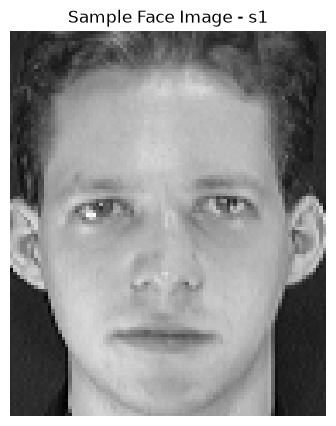

In [9]:
# Display the sample image
plt.figure(figsize=(5, 5))
plt.imshow(sample_array, cmap="gray")
plt.title("Sample Face Image - " + first_subject)
plt.axis("off")
plt.show()

In [10]:
#Convert one image into a feature vector
image_vector = sample_array.flatten()

print("Original image shape:", sample_array.shape)
print("Flattened vector shape:", image_vector.shape)
print("Number of pixel features:", len(image_vector))

Original image shape: (112, 92)
Flattened vector shape: (10304,)
Number of pixel features: 10304


In [11]:
#Load all images and labels

images = []
labels = []

image_extensions = (".pgm", ".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff")

for subject in subject_folders:
    subject_path = os.path.join(dataset_path, subject)

    image_files = sorted(
        file for file in os.listdir(subject_path)
        if file.lower().endswith(image_extensions)
        and os.path.isfile(os.path.join(subject_path, file))
    )

    for file in image_files:
        image_path = os.path.join(subject_path, file)

        image = Image.open(image_path).convert("L")
        image_array = np.array(image)

        images.append(image_array.flatten())
        labels.append(subject)

X = np.array(images)
y = np.array(labels)

print("Image matrix shape:", X.shape)
print("Label array shape:", y.shape)
print("Total images:", len(X))
print("Unique subjects:", len(np.unique(y)))

Image matrix shape: (400, 10304)
Label array shape: (400,)
Total images: 400
Unique subjects: 40


In [12]:
# Check image counts per subject

unique_subjects, subject_counts = np.unique(y, return_counts=True)

print("Images per subject:")

for subject, count in zip(unique_subjects, subject_counts):
    print(subject, ":", count)

print("\nMinimum images per subject:", subject_counts.min())
print("Maximum images per subject:", subject_counts.max())

Images per subject:
s1 : 10
s10 : 10
s11 : 10
s12 : 10
s13 : 10
s14 : 10
s15 : 10
s16 : 10
s17 : 10
s18 : 10
s19 : 10
s2 : 10
s20 : 10
s21 : 10
s22 : 10
s23 : 10
s24 : 10
s25 : 10
s26 : 10
s27 : 10
s28 : 10
s29 : 10
s3 : 10
s30 : 10
s31 : 10
s32 : 10
s33 : 10
s34 : 10
s35 : 10
s36 : 10
s37 : 10
s38 : 10
s39 : 10
s4 : 10
s40 : 10
s5 : 10
s6 : 10
s7 : 10
s8 : 10
s9 : 10

Minimum images per subject: 10
Maximum images per subject: 10


### Train/Test Split


In [13]:
# Split images for every subject

from sklearn.model_selection import train_test_split

train_indices = []
test_indices = []

for subject in unique_subjects:
    subject_indices = np.where(y == subject)[0]

    subject_train, subject_test = train_test_split(
        subject_indices,
        test_size=0.3,
        random_state=42
    )

    train_indices.extend(subject_train)
    test_indices.extend(subject_test)

train_indices = np.array(train_indices)
test_indices = np.array(test_indices)

X_train = X[train_indices]
X_test = X[test_indices]

y_train = y[train_indices]
y_test = y[test_indices]

print("Training images:", X_train.shape[0])
print("Testing images:", X_test.shape[0])
print("Training feature matrix:", X_train.shape)
print("Testing feature matrix:", X_test.shape)

Training images: 280
Testing images: 120
Training feature matrix: (280, 10304)
Testing feature matrix: (120, 10304)


In [14]:
# Verify subject representation
train_subjects = np.unique(y_train)
test_subjects = np.unique(y_test)

print("Subjects in training set:", len(train_subjects))
print("Subjects in testing set:", len(test_subjects))

print("All training subjects are represented in testing:",
      set(train_subjects) == set(test_subjects))

print("Training images per subject:")
for subject in unique_subjects:
    print(subject, ":", np.sum(y_train == subject))

print("\nTesting images per subject:")
for subject in unique_subjects:
    print(subject, ":", np.sum(y_test == subject))

Subjects in training set: 40
Subjects in testing set: 40
All training subjects are represented in testing: True
Training images per subject:
s1 : 7
s10 : 7
s11 : 7
s12 : 7
s13 : 7
s14 : 7
s15 : 7
s16 : 7
s17 : 7
s18 : 7
s19 : 7
s2 : 7
s20 : 7
s21 : 7
s22 : 7
s23 : 7
s24 : 7
s25 : 7
s26 : 7
s27 : 7
s28 : 7
s29 : 7
s3 : 7
s30 : 7
s31 : 7
s32 : 7
s33 : 7
s34 : 7
s35 : 7
s36 : 7
s37 : 7
s38 : 7
s39 : 7
s4 : 7
s40 : 7
s5 : 7
s6 : 7
s7 : 7
s8 : 7
s9 : 7

Testing images per subject:
s1 : 3
s10 : 3
s11 : 3
s12 : 3
s13 : 3
s14 : 3
s15 : 3
s16 : 3
s17 : 3
s18 : 3
s19 : 3
s2 : 3
s20 : 3
s21 : 3
s22 : 3
s23 : 3
s24 : 3
s25 : 3
s26 : 3
s27 : 3
s28 : 3
s29 : 3
s3 : 3
s30 : 3
s31 : 3
s32 : 3
s33 : 3
s34 : 3
s35 : 3
s36 : 3
s37 : 3
s38 : 3
s39 : 3
s4 : 3
s40 : 3
s5 : 3
s6 : 3
s7 : 3
s8 : 3
s9 : 3


## Part B: PCA, Eigenfaces and Compression



In [15]:
# Prepare and center the training data

# Convert pixel values to floating-point numbers
X_train_float = X_train.astype(np.float64)
X_test_float = X_test.astype(np.float64)

# Calculate the mean face using training images only
mean_face = np.mean(X_train_float, axis=0)

# Center the training and testing data
X_train_centered = X_train_float - mean_face
X_test_centered = X_test_float - mean_face

print("Mean face vector shape:", mean_face.shape)
print("Centered training matrix shape:", X_train_centered.shape)
print("Centered testing matrix shape:", X_test_centered.shape)

Mean face vector shape: (10304,)
Centered training matrix shape: (280, 10304)
Centered testing matrix shape: (120, 10304)


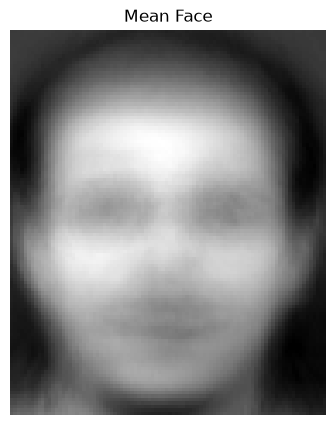

In [16]:
height, width = sample_array.shape

mean_face_image = mean_face.reshape(height, width)

plt.figure(figsize=(5, 5))
plt.imshow(mean_face_image, cmap="gray")
plt.title("Mean Face")
plt.axis("off")
plt.show()

In [17]:
# Calculate the dual covariance matrix
number_of_training_images = X_train_centered.shape[0]

dual_covariance = (
    X_train_centered @ X_train_centered.T
) / (number_of_training_images - 1)

# Calculate eigenvalues and eigenvectors
eigenvalues, eigenvectors = np.linalg.eigh(dual_covariance)

# Sort eigenvalues from largest to smallest
order = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[order]
eigenvectors = eigenvectors[:, order]

# Ignore tiny negative values caused by numerical precision
eigenvalues = np.maximum(eigenvalues, 0)

# Convert eigenvectors into directions in pixel space
positive = eigenvalues > 1e-10

eigenvalues_cov = eigenvalues[positive]
eigenvectors_cov = eigenvectors[:, positive]

principal_directions_cov = (
    X_train_centered.T @ eigenvectors_cov
) / np.sqrt(
    (number_of_training_images - 1) * eigenvalues_cov
)

print("Dual covariance matrix shape:", dual_covariance.shape)
print("Principal directions shape:", principal_directions_cov.shape)
print("Number of retained positive eigenvalues:", len(eigenvalues_cov))

Dual covariance matrix shape: (280, 280)
Principal directions shape: (10304, 279)
Number of retained positive eigenvalues: 279


In [ ]:
# Compute PCA using SVD

U, singular_values, Vt = np.linalg.svd(
    X_train_centered,
    full_matrices=False
)

# Principal directions are rows of Vt
principal_directions_svd = Vt.T

# Calculate the variance explained by each singular value
eigenvalues_svd = (
    singular_values ** 2
) / (number_of_training_images - 1)

print("U shape:", U.shape)
print("Singular values shape:", singular_values.shape)
print("SVD principal directions shape:", principal_directions_svd.shape)

U shape: (280, 280)
Singular values shape: (280,)
SVD principal directions shape: (10304, 280)


In [19]:
# Compare the two approaches 
number_to_compare = min(
    20,
    principal_directions_cov.shape[1],
    principal_directions_svd.shape[1]
)

# Compare the corresponding principal directions
direction_correlations = []

for i in range(number_to_compare):
    covariance_direction = principal_directions_cov[:, i]
    svd_direction = principal_directions_svd[:, i]

    correlation = abs(
        np.dot(covariance_direction, svd_direction)
    )

    direction_correlations.append(correlation)

print("Absolute direction similarities for the first components:")
print(np.round(direction_correlations, 6))

print(
    "\nAverage similarity:",
    np.mean(direction_correlations)
)

Absolute direction similarities for the first components:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]

Average similarity: 1.0


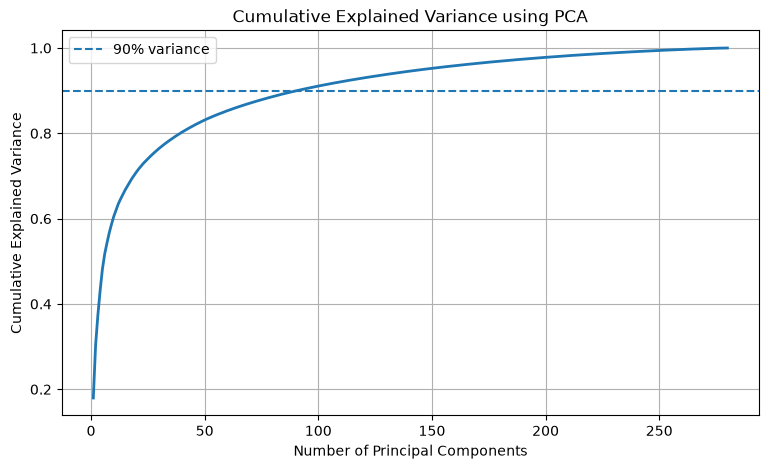

In [20]:
# Plot cumulative explained variance

total_variance = np.sum(eigenvalues_svd)

explained_variance_ratio = eigenvalues_svd / total_variance
cumulative_variance = np.cumsum(explained_variance_ratio)

plt.figure(figsize=(9, 5))
plt.plot(
    np.arange(1, len(cumulative_variance) + 1),
    cumulative_variance,
    linewidth=2
)
plt.axhline(y=0.90, linestyle="--", label="90% variance")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("Cumulative Explained Variance using PCA")
plt.grid(True)
plt.legend()
plt.show()

In [21]:
# Find the minimum components for 90% variance

required_variance = 0.90

number_of_components = (
    np.searchsorted(cumulative_variance, required_variance) + 1
)

print("Required variance:", required_variance * 100, "%")
print("Minimum number of components:", number_of_components)
print(
    "Variance preserved:",
    round(cumulative_variance[number_of_components - 1] * 100, 2),
    "%"
)

Required variance: 90.0 %
Minimum number of components: 91
Variance preserved: 90.06 %


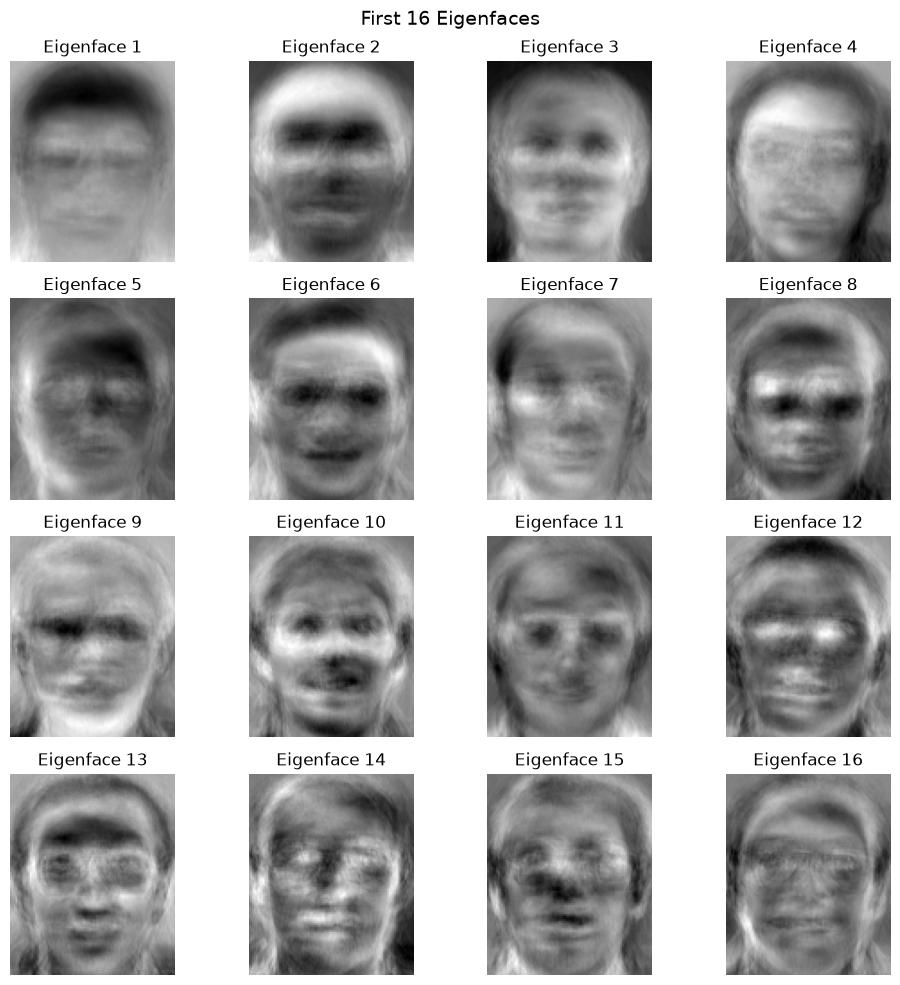

In [22]:
# Visualize the first 16 eigenfaces

selected_directions = principal_directions_svd[:, :number_of_components]

number_to_display = min(16, number_of_components)

fig, axes = plt.subplots(4, 4, figsize=(10, 10))

for i, ax in enumerate(axes.flat):
    if i < number_to_display:
        eigenface = selected_directions[:, i].reshape(height, width)
        ax.imshow(eigenface, cmap="gray")
        ax.set_title("Eigenface " + str(i + 1))
    ax.axis("off")

plt.suptitle("First 16 Eigenfaces", fontsize=14)
plt.tight_layout()
plt.show()

In [ ]:
# Project images into PCA space

selected_directions = principal_directions_svd[:, :number_of_components]

# Project training and testing images into PCA space
X_train_pca = X_train_centered @ selected_directions
X_test_pca = X_test_centered @ selected_directions

print("Training PCA representation:", X_train_pca.shape)
print("Testing PCA representation:", X_test_pca.shape)
print("Components retained:", number_of_components)

Training PCA representation: (280, 91)
Testing PCA representation: (120, 91)
Components retained: 91


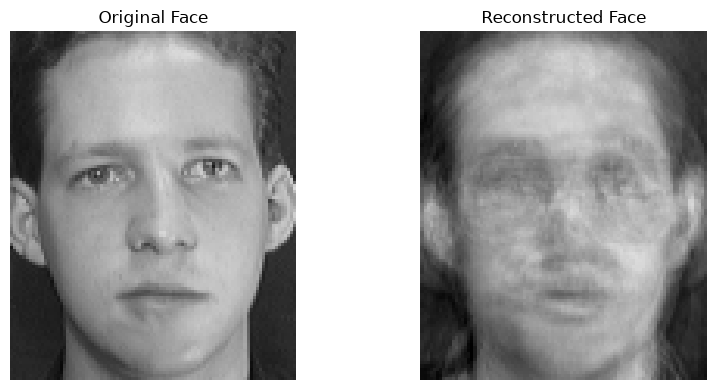

In [24]:
sample_index = 0

# Original test image
original_face = X_test_float[sample_index]

# Center and project the image
centered_face = original_face - mean_face
face_coefficients = centered_face @ selected_directions

# Reconstruct the face from the PCA coefficients
reconstructed_face = (
    face_coefficients @ selected_directions.T
) + mean_face

original_image = original_face.reshape(height, width)
reconstructed_image = reconstructed_face.reshape(height, width)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))

axes[0].imshow(original_image, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original Face")
axes[0].axis("off")

axes[1].imshow(reconstructed_image, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Reconstructed Face")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [25]:
# Calculate mean squared error for the selected test image
sample_mse = np.mean(
    (original_face - reconstructed_face) ** 2
)

# Reconstruct all test images
X_test_reconstructed = (
    X_test_pca @ selected_directions.T
) + mean_face

# Calculate overall reconstruction error
test_mse = np.mean(
    (X_test_float - X_test_reconstructed) ** 2
)

print("Sample reconstruction MSE:", round(sample_mse, 2))
print("Overall test reconstruction MSE:", round(test_mse, 2))

Sample reconstruction MSE: 306.72
Overall test reconstruction MSE: 345.38


In [26]:
# Number of values needed to represent one image
original_values_per_image = X.shape[1]
pca_values_per_image = number_of_components

# Compare values per image
reduction_percentage = (
    1 - pca_values_per_image / original_values_per_image
) * 100

# Estimate storage for the full dataset using uint8 original pixels
original_storage_bytes = X.size * np.dtype(np.uint8).itemsize

# Estimate PCA storage using float64 coefficients, mean face and components
pca_coefficients_bytes = (
    len(X) * number_of_components * np.dtype(np.float64).itemsize
)
mean_face_bytes = mean_face.nbytes
eigenfaces_bytes = selected_directions.nbytes

total_pca_storage_bytes = (
    pca_coefficients_bytes + mean_face_bytes + eigenfaces_bytes
)

print("Original values per image:", original_values_per_image)
print("PCA values per image:", pca_values_per_image)
print("Reduction in values per image:", round(reduction_percentage, 2), "%")

print("\nOriginal image storage (uint8):",
      round(original_storage_bytes / 1024, 2), "KB")

print("PCA coefficients storage:",
      round(pca_coefficients_bytes / 1024, 2), "KB")

print("Mean face storage:",
      round(mean_face_bytes / 1024, 2), "KB")

print("Selected eigenfaces storage:",
      round(eigenfaces_bytes / 1024, 2), "KB")

print("Total PCA storage estimate:",
      round(total_pca_storage_bytes / 1024, 2), "KB")

Original values per image: 10304
PCA values per image: 91
Reduction in values per image: 99.12 %

Original image storage (uint8): 4025.0 KB
PCA coefficients storage: 284.38 KB
Mean face storage: 80.5 KB
Selected eigenfaces storage: 7325.5 KB
Total PCA storage estimate: 7690.38 KB


## Part C: Recognition in PCA Space

In [27]:
# Euclidean nearest-face recognition

def nearest_face_recognition(X_train_features, y_train, X_test_features):
    predictions = []
    nearest_indices = []
    nearest_distances = []

    for test_face in X_test_features:
        differences = X_train_features - test_face

        distances = np.sqrt(
            np.sum(differences ** 2, axis=1)
        )

        closest_index = np.argmin(distances)

        predictions.append(y_train[closest_index])
        nearest_indices.append(closest_index)
        nearest_distances.append(distances[closest_index])

    return (
        np.array(predictions),
        np.array(nearest_indices),
        np.array(nearest_distances)
    )

In [28]:
# Recognize faces using raw pixels
raw_predictions, raw_nearest_indices, raw_nearest_distances = (
    nearest_face_recognition(
        X_train_float,
        y_train,
        X_test_float
    )
)

raw_accuracy = np.mean(raw_predictions == y_test) * 100

print("Raw pixel recognition accuracy:",
      round(raw_accuracy, 2), "%")
print("Correct predictions:",
      np.sum(raw_predictions == y_test))
print("Incorrect predictions:",
      np.sum(raw_predictions != y_test))
print("Total test images:", len(y_test))


Raw pixel recognition accuracy: 95.83 %
Correct predictions: 115
Incorrect predictions: 5
Total test images: 120


In [29]:
# Recognize faces using PCA features

pca_predictions, pca_nearest_indices, pca_nearest_distances = (
    nearest_face_recognition(
        X_train_pca,
        y_train,
        X_test_pca
    )
)

pca_accuracy = np.mean(pca_predictions == y_test) * 100

print("PCA recognition accuracy:",
      round(pca_accuracy, 2), "%")
print("Correct predictions:",
      np.sum(pca_predictions == y_test))
print("Incorrect predictions:",
      np.sum(pca_predictions != y_test))
print("Total test images:", len(y_test))

PCA recognition accuracy: 95.83 %
Correct predictions: 115
Incorrect predictions: 5
Total test images: 120


In [30]:
# Compare recognition accuracy

print("Recognition Accuracy Comparison")
print("Raw pixels:", round(raw_accuracy, 2), "%")
print("PCA features:", round(pca_accuracy, 2), "%")

accuracy_difference = pca_accuracy - raw_accuracy

print("PCA minus raw accuracy:",
      round(accuracy_difference, 2), "percentage points")

Recognition Accuracy Comparison
Raw pixels: 95.83 %
PCA features: 95.83 %
PCA minus raw accuracy: 0.0 percentage points


In [31]:
# Display correct and incorrect matches

correct_indices = np.where(pca_predictions == y_test)[0]
incorrect_indices = np.where(pca_predictions != y_test)[0]

print("Number of correct PCA matches:", len(correct_indices))
print("Number of incorrect PCA matches:", len(incorrect_indices))

Number of correct PCA matches: 115
Number of incorrect PCA matches: 5


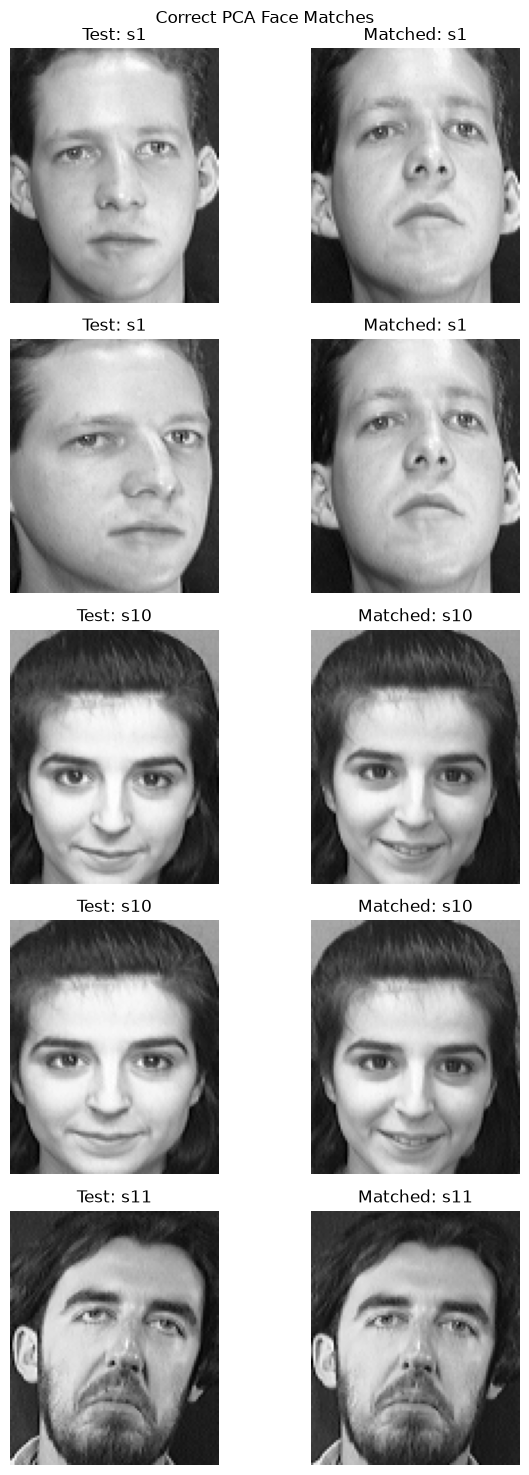

In [32]:
# Visualize a few correct PCA matches
number_to_show = min(5, len(correct_indices))

if number_to_show > 0:
    fig, axes = plt.subplots(
        number_to_show, 2,
        figsize=(7, 3 * number_to_show)
    )

    if number_to_show == 1:
        axes = np.array([axes])

    for row, test_index in enumerate(correct_indices[:number_to_show]):
        train_index = pca_nearest_indices[test_index]

        test_face = X_test_float[test_index].reshape(height, width)
        matched_face = X_train_float[train_index].reshape(height, width)

        axes[row, 0].imshow(test_face, cmap="gray")
        axes[row, 0].set_title(
            "Test: " + str(y_test[test_index])
        )

        axes[row, 1].imshow(matched_face, cmap="gray")
        axes[row, 1].set_title(
            "Matched: " + str(y_train[train_index])
        )

        axes[row, 0].axis("off")
        axes[row, 1].axis("off")

    plt.suptitle("Correct PCA Face Matches")
    plt.tight_layout()
    plt.show()
else:
    print("No correct PCA matches to display.")

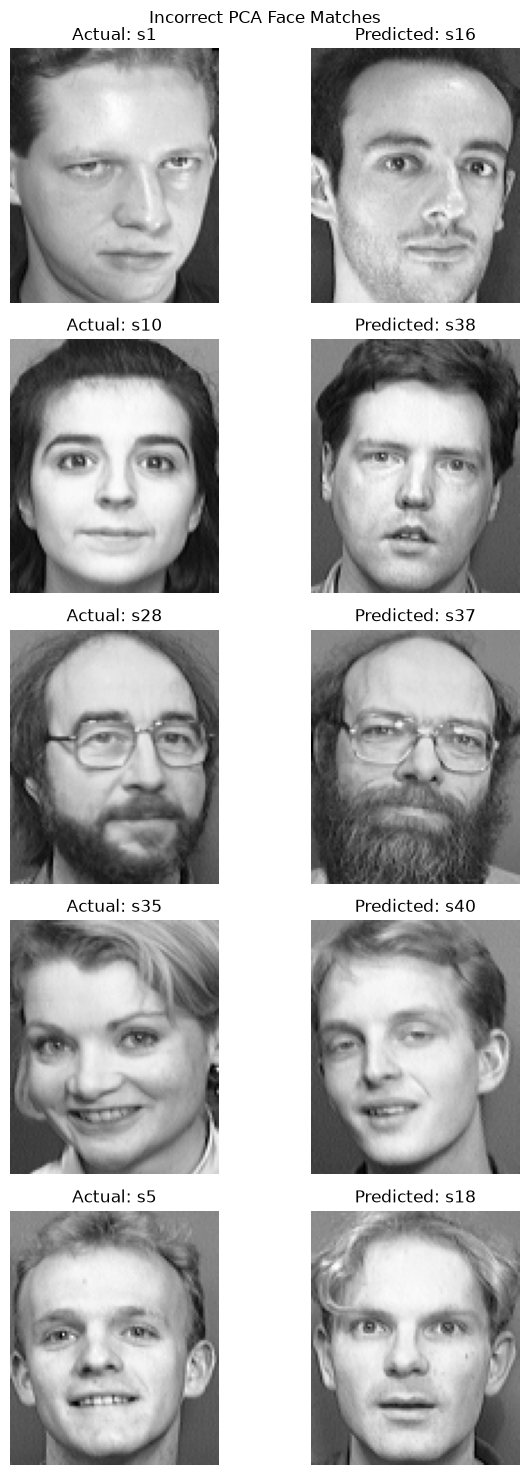

In [33]:
# Visualize a few incorrect PCA matches

number_to_show = min(5, len(incorrect_indices))

if number_to_show > 0:
    fig, axes = plt.subplots(
        number_to_show, 2,
        figsize=(7, 3 * number_to_show)
    )

    if number_to_show == 1:
        axes = np.array([axes])

    for row, test_index in enumerate(incorrect_indices[:number_to_show]):
        train_index = pca_nearest_indices[test_index]

        test_face = X_test_float[test_index].reshape(height, width)
        matched_face = X_train_float[train_index].reshape(height, width)

        axes[row, 0].imshow(test_face, cmap="gray")
        axes[row, 0].set_title(
            "Actual: " + str(y_test[test_index])
        )

        axes[row, 1].imshow(matched_face, cmap="gray")
        axes[row, 1].set_title(
            "Predicted: " + str(y_train[train_index])
        )

        axes[row, 0].axis("off")
        axes[row, 1].axis("off")

    plt.suptitle("Incorrect PCA Face Matches")
    plt.tight_layout()
    plt.show()
else:
    print("No incorrect PCA matches to display.")

In [34]:
# comparison table
print("Method              Accuracy (%)    Correct    Incorrect")

print(
    f"{'Raw pixels':<20}"
    f"{raw_accuracy:<16.2f}"
    f"{np.sum(raw_predictions == y_test):<11}"
    f"{np.sum(raw_predictions != y_test)}"
)

print(
    f"{'PCA features':<20}"
    f"{pca_accuracy:<16.2f}"
    f"{np.sum(pca_predictions == y_test):<11}"
    f"{np.sum(pca_predictions != y_test)}"
)

Method              Accuracy (%)    Correct    Incorrect
Raw pixels          95.83           115        5
PCA features        95.83           115        5


## Part D: Traditional Machine Learning


In [35]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

In [36]:
# Train three classifiers using the 90% PCA representation

# K-Nearest Neighbors
knn_model = KNeighborsClassifier(n_neighbors=3)
knn_model.fit(X_train_pca, y_train)
knn_predictions = knn_model.predict(X_test_pca)

# Logistic Regression
logistic_model = LogisticRegression(max_iter=3000, random_state=42)
logistic_model.fit(X_train_pca, y_train)
logistic_predictions = logistic_model.predict(X_test_pca)

# Support Vector Machine
svm_model = SVC(kernel="rbf", C=10, gamma="scale")
svm_model.fit(X_train_pca, y_train)
svm_predictions = svm_model.predict(X_test_pca)

# Calculate accuracy
knn_accuracy = accuracy_score(y_test, knn_predictions) * 100
logistic_accuracy = accuracy_score(y_test, logistic_predictions) * 100
svm_accuracy = accuracy_score(y_test, svm_predictions) * 100

print("KNN accuracy:", round(knn_accuracy, 2), "%")
print("Logistic Regression accuracy:", round(logistic_accuracy, 2), "%")
print("SVM accuracy:", round(svm_accuracy, 2), "%")

KNN accuracy: 91.67 %
Logistic Regression accuracy: 96.67 %
SVM accuracy: 96.67 %


Recognition method comparison
------------------------------------------------
Raw pixel nearest face    95.83%
PCA nearest face          95.83%
KNN                       91.67%
Logistic Regression       96.67%
SVM                       96.67%


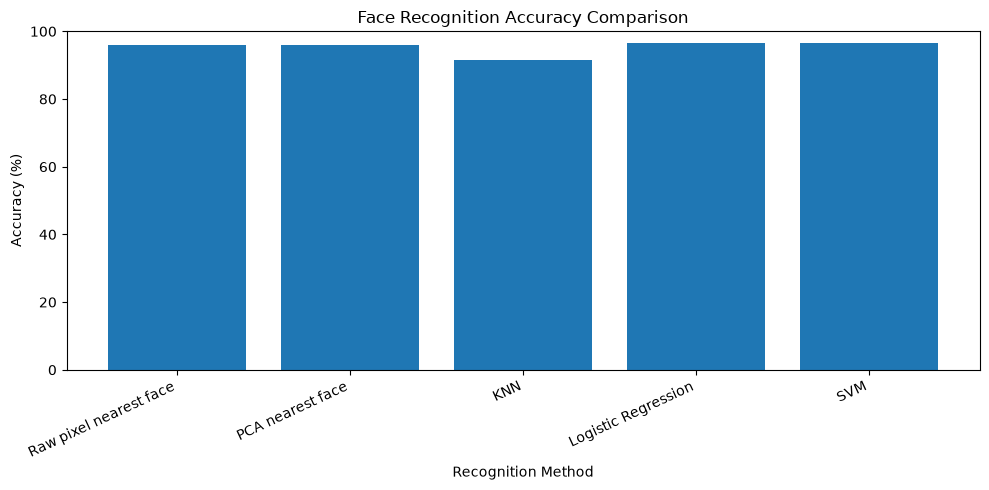

In [37]:
# Compare all methods
method_names = [
    "Raw pixel nearest face",
    "PCA nearest face",
    "KNN",
    "Logistic Regression",
    "SVM"
]

accuracies = [
    raw_accuracy,
    pca_accuracy,
    knn_accuracy,
    logistic_accuracy,
    svm_accuracy
]

print("Recognition method comparison")
print("-" * 48)

for method, accuracy in zip(method_names, accuracies):
    print(f"{method:<25} {accuracy:.2f}%")

plt.figure(figsize=(10, 5))
plt.bar(method_names, accuracies)
plt.ylabel("Accuracy (%)")
plt.xlabel("Recognition Method")
plt.title("Face Recognition Accuracy Comparison")
plt.ylim(0, 100)
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

In [38]:
# Compare different component counts

candidate_components = [
    count for count in [20, 40, 60, 80, 100, number_of_components]
    if count <= principal_directions_svd.shape[1]
]

# Remove duplicate values and sort
candidate_components = sorted(set(candidate_components))

component_results = []

for count in candidate_components:
    directions = principal_directions_svd[:, :count]

    # Project data using the selected components
    train_features = X_train_centered @ directions
    test_features = X_test_centered @ directions

    # KNN
    knn = KNeighborsClassifier(n_neighbors=3)
    knn.fit(train_features, y_train)
    knn_acc = accuracy_score(y_test, knn.predict(test_features)) * 100

    # SVM
    svm = SVC(kernel="rbf", C=10, gamma="scale")
    svm.fit(train_features, y_train)
    svm_acc = accuracy_score(y_test, svm.predict(test_features)) * 100

    component_results.append((count, knn_acc, svm_acc))

    print(
        "Components:", count,
        "| KNN:", round(knn_acc, 2), "%",
        "| SVM:", round(svm_acc, 2), "%"
    )

Components: 20 | KNN: 91.67 % | SVM: 96.67 %
Components: 40 | KNN: 93.33 % | SVM: 95.83 %
Components: 60 | KNN: 92.5 % | SVM: 95.83 %
Components: 80 | KNN: 91.67 % | SVM: 96.67 %
Components: 91 | KNN: 91.67 % | SVM: 96.67 %
Components: 100 | KNN: 90.0 % | SVM: 96.67 %


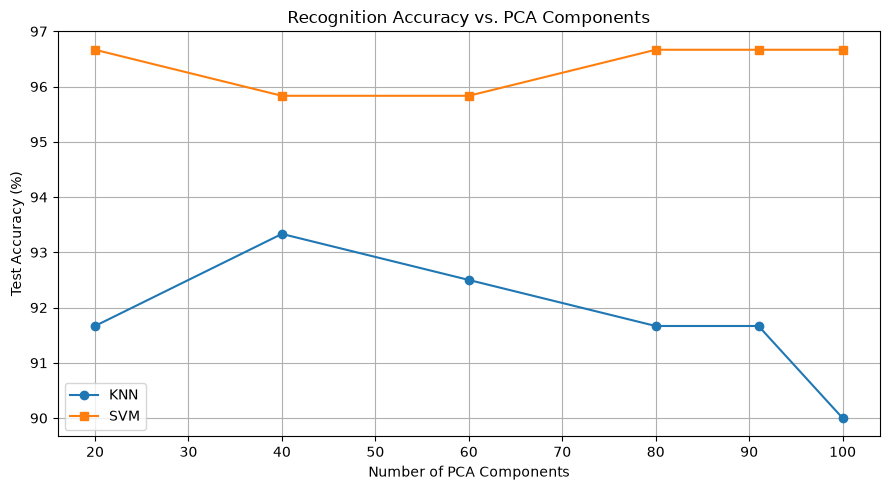

In [39]:
# Visualize the component experiment
component_counts = [row[0] for row in component_results]
knn_scores = [row[1] for row in component_results]
svm_scores = [row[2] for row in component_results]

plt.figure(figsize=(9, 5))
plt.plot(
    component_counts, knn_scores,
    marker="o", label="KNN"
)
plt.plot(
    component_counts, svm_scores,
    marker="s", label="SVM"
)

plt.xlabel("Number of PCA Components")
plt.ylabel("Test Accuracy (%)")
plt.title("Recognition Accuracy vs. PCA Components")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

In [40]:
# Find the best tested configuration

best_knn_result = max(component_results, key=lambda row: row[1])
best_svm_result = max(component_results, key=lambda row: row[2])

print("Best tested KNN configuration")
print("Components:", best_knn_result[0])
print("Accuracy:", round(best_knn_result[1], 2), "%")

print("\nBest tested SVM configuration")
print("Components:", best_svm_result[0])
print("Accuracy:", round(best_svm_result[2], 2), "%")

Best tested KNN configuration
Components: 40
Accuracy: 93.33 %

Best tested SVM configuration
Components: 20
Accuracy: 96.67 %


In [41]:
# Summarize compactness and accuracy
print("PCA representation summary")
print("-" * 40)
print("Original pixel features per image:", X.shape[1])
print("Components required for 90% variance:", number_of_components)
print(
    "Feature reduction at 90% variance:",
    round((1 - number_of_components / X.shape[1]) * 100, 2),
    "%"
)

print("\nBest tested KNN accuracy:",
      round(best_knn_result[1], 2), "%")
print("Best tested SVM accuracy:",
      round(best_svm_result[2], 2), "%")

PCA representation summary
----------------------------------------
Original pixel features per image: 10304
Components required for 90% variance: 91
Feature reduction at 90% variance: 99.12 %

Best tested KNN accuracy: 93.33 %
Best tested SVM accuracy: 96.67 %
